<a href="https://colab.research.google.com/github/AmalKrishna212121/Capstone-Project-Group-3/blob/main/Capstone_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Chip setup: 10.0x10.0 mm, N=40x40, Interior DOFs=1444
Grid spacing h = 0.2564 mm, Thickness d = 150.0 um

--- STAGE 3: SymPy Verification of Transient Response ---
Laplace transform identity verified: U(s) - (P0/s)*Z_th(s) = 0
Fundamental thermal time constant tau_11 = 55.05 ms

Sparse system matrix A assembled: 1444x1444, non-zeros: 7068 (0.34% dense)

Thermal Resistance Matrix Z_th(0) [K/W] for Scenario 1:
       B1       B2       B3       B4
B1    30.03     1.35     1.35     0.74
B2     1.35    30.03     0.74     1.35
B3     1.35     0.74    30.03     1.35
B4     0.74     1.35     1.35    30.03

TABLE 1: PEAK TEMPERATURE SUMMARY (P_max = 5 W)
Scenario 1 (Symmetric)   | Uniform: 341.83 K | LP: 341.83 K | Red.: 0.00 K
  Allocation q (W): [1.25 1.25 1.25 1.25]
Scenario 2 (Asymmetric)  | Uniform: 359.04 K | LP: 347.40 K | Red.: 11.64 K
  Allocation q (W): [1.82 0.94 1.12 1.12]


/tmp/ipykernel_1235/94451936.py:277: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


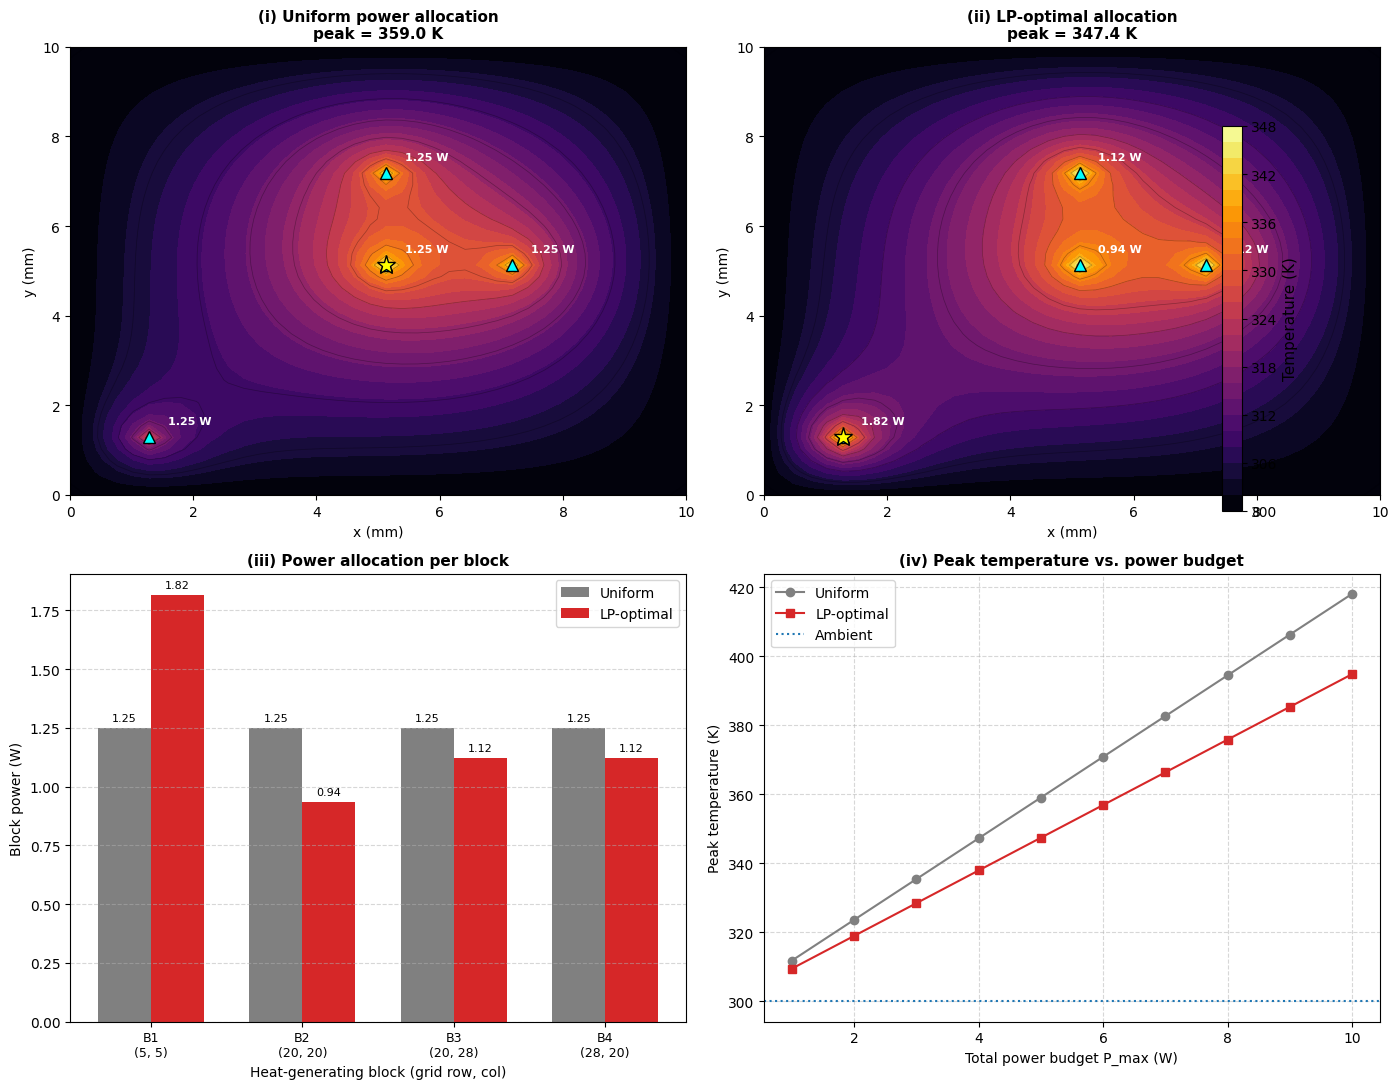


--- Running Convergence Verification ---


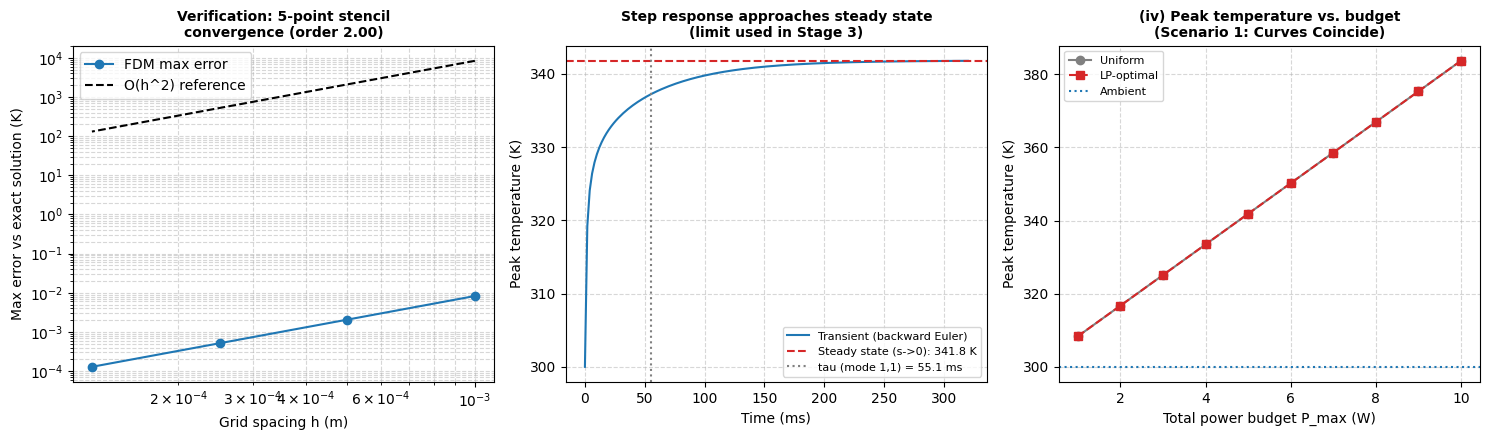


VERIFICATION SANITY CHECKS:
1. FDM Convergence Order: 2.00 (Expected: ~2.00)
2. Reciprocity max |Z_th - Z_th^T|: 1.33e-15 (Expected: < 1e-9)
3. Transient Peak at 320 ms: 341.79 K vs Steady-State: 341.83 K
4.y LP epigraph t (47.4032 K) == PDE peak rise (47.4032 K), diff = 2.13e-14


In [2]:

# ==============================================================================
# Capstone Project: Thermal-Aware Power Budgeting on a Chip (Odd Group 3)
# Pipeline: PDE (Poisson) -> Laplace -> Sparse FDM -> LP (HiGHS) -> Verification
# ==============================================================================

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.optimize import linprog
import matplotlib.pyplot as plt
import sympy as smp

# ------------------------------------------------------------------------------
# 1. PHYSICAL CONSTANTS & PARAMETERS
# ------------------------------------------------------------------------------
L = 10e-3               # Die side length: 10 mm (m)
k_therm = 150.0         # Thermal conductivity of Silicon: 150 W/(m·K)
d = 150e-6              # Die thickness: 150 um (m)
rho_c = 1.63e6          # Volumetric heat capacity of Silicon: 1.63e6 J/(m^3·K)
T_amb = 300.0           # Ambient temperature on boundary: 300 K
P_max = 5.0             # Total power budget: 5 W

N = 40                  # Grid resolution: 40 x 40
n = N - 2               # Interior nodes per dimension: 38 (total = 1444)
h = L / (N - 1)         # Grid spacing (m)
x = np.linspace(0, L, N)
y = np.linspace(0, L, N)
X, Y = np.meshgrid(x, y)

# Block Coordinates (grid indices [row, col] on 0-indexed N=40 grid)
# Scenario 1 (Symmetric layout from brief)
blocks_sc1 = [(10, 10), (10, 29), (29, 10), (29, 29)]

# Scenario 2 (Asymmetric layout)
blocks_sc2 = [(5, 5), (20, 20), (20, 28), (28, 20)]

print("="*70)
print(f"Chip setup: {L*1e3:.1f}x{L*1e3:.1f} mm, N={N}x{N}, Interior DOFs={n*n}")
print(f"Grid spacing h = {h*1e3:.4f} mm, Thickness d = {d*1e6:.1f} um")
print("="*70)

# ------------------------------------------------------------------------------
# 2. STAGE 3: SYMBOLIC LAPLACE / RC STAGES VERIFICATION (SymPy)
# ------------------------------------------------------------------------------
print("\n--- STAGE 3: SymPy Verification of Transient Response ---")
s_sym, t_sym, R_sym, C_sym, P0_sym = smp.symbols('s t R C P0', positive=True)
tau_sym = R_sym * C_sym

# Time-domain step response of first-order thermal RC stage
u_t = P0_sym * R_sym * (1 - smp.exp(-t_sym / tau_sym))

# Laplace transform of u(t)
U_s = smp.laplace_transform(u_t, t_sym, s_sym)[0]

# Expected frequency-domain representation: P(s) * Z_th(s) where P(s) = P0/s
Z_th_s = R_sym / (1 + s_sym * tau_sym)
expected_U_s = (P0_sym / s_sym) * Z_th_s

diff = smp.simplify(U_s - expected_U_s)
print(f"Laplace transform identity verified: U(s) - (P0/s)*Z_th(s) = {diff}")

# Theoretical dominant time constant tau_11
lambda_11 = 2 * (np.pi / L)**2
tau_11 = (rho_c) / (k_therm * lambda_11)
print(f"Fundamental thermal time constant tau_11 = {tau_11*1e3:.2f} ms")

# ------------------------------------------------------------------------------
# 3. STAGE 4: SPARSE FDM OPERATOR & GREEN'S FUNCTION
# ------------------------------------------------------------------------------
def build_fdm_system(N_grid):
    n_in = N_grid - 2
    h_step = L / (N_grid - 1)

    # 1D 2nd derivative tridiagonal matrix D = tridiag(1, -2, 1)
    main_diag = -2.0 * np.ones(n_in)
    off_diag = np.ones(n_in - 1)
    D = sp.diags([off_diag, main_diag, off_diag], [-1, 0, 1], shape=(n_in, n_in))

    # 2D 5-point Laplacian via Kronecker product: A = (I (x) D + D (x) I) / h^2
    I_n = sp.eye(n_in)
    A = sp.kron(I_n, D) + sp.kron(D, I_n)
    A = (A / (h_step**2)).tocsc()
    return A, h_step, n_in

A, h, n = build_fdm_system(N)
print(f"\nSparse system matrix A assembled: {A.shape[0]}x{A.shape[1]}, non-zeros: {A.nnz} ({A.nnz / A.shape[0]**2 * 100:.2f}% dense)")

# Factorize A once with SuperLU
A_lu = spla.splu(A)

def get_mapping_matrix_G(blocks, N_grid, A_lu_solver):
    """
    Constructs G = -A^(-1) * B such that u_interior = G * q
    """
    n_in = N_grid - 2
    h_step = L / (N_grid - 1)
    G = np.zeros((n_in * n_in, len(blocks)))

    for b_idx, (r, c) in enumerate(blocks):
        # Map (row, col) in N-grid to interior index
        r_in = r - 1
        c_in = c - 1
        flat_idx = r_in * n_in + c_in

        # B column: unit point source scaled by 1 / (k * d * h^2)
        b_vec = np.zeros(n_in * n_in)
        b_vec[flat_idx] = 1.0 / (k_therm * d * (h_step**2))

        # Solve A * u = - B * q_unit => u = - A^(-1) * B
        G[:, b_idx] = A_lu_solver.solve(-b_vec)
    return G

# Compute thermal resistance matrix Z_th(0) for Scenario 1
G_sc1 = get_mapping_matrix_G(blocks_sc1, N, A_lu)
Z_th_sc1 = np.zeros((4, 4))
for i, (r_i, c_i) in enumerate(blocks_sc1):
    flat_i = (r_i - 1) * n + (c_i - 1)
    for j in range(4):
        Z_th_sc1[i, j] = G_sc1[flat_i, j]

print("\nThermal Resistance Matrix Z_th(0) [K/W] for Scenario 1:")
print("       B1       B2       B3       B4")
for i in range(4):
    row_str = f"B{i+1} " + " ".join([f"{Z_th_sc1[i, j]:8.2f}" for j in range(4)])
    print(row_str)

# ------------------------------------------------------------------------------
# 4. STAGE 5: LINEAR PROGRAMMING OPTIMIZATION (HiGHS)
# ------------------------------------------------------------------------------
def solve_thermal_budget_lp(G_mat, P_total):
    """
    Solves: min t
            s.t.  u = G * q
                  sum(q_i) = P_total
                  u_i - t <= 0
                 -u_i - t <= 0
                  q_i >= 0, t >= 0
    Variables z = [q (4), t (1)]
    """
    n_points = G_mat.shape[0]
    n_blocks = G_mat.shape[1]

    # Cost c: [0, ..., 0, 1]
    c = np.zeros(n_blocks + 1)
    c[-1] = 1.0

    # Inequalities:
    #  G*q - t*1 <= 0  ==>  [ G, -1 ] * z <= 0
    # -G*q - t*1 <= 0  ==>  [-G, -1 ] * z <= 0
    A_ub = np.vstack([
        np.hstack([G_mat, -np.ones((n_points, 1))]),
        np.hstack([-G_mat, -np.ones((n_points, 1))])
    ])
    b_ub = np.zeros(2 * n_points)

    # Equality: sum(q) = P_total
    A_eq = np.zeros((1, n_blocks + 1))
    A_eq[0, :n_blocks] = 1.0
    b_eq = np.array([P_total])

    bounds = [(0, None)] * (n_blocks + 1)

    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')

    q_opt = res.x[:n_blocks]
    t_opt = res.x[-1]
    return q_opt, t_opt, res.success

# Solve for Scenario 1 and 2
q_unif = np.full(4, P_max / 4.0)

# Scenario 1 Solve
q_opt_sc1, t_opt_sc1, ok1 = solve_thermal_budget_lp(G_sc1, P_max)
T_field_unif_sc1 = T_amb + G_sc1 @ q_unif
T_field_opt_sc1  = T_amb + G_sc1 @ q_opt_sc1

# Scenario 2 Solve
G_sc2 = get_mapping_matrix_G(blocks_sc2, N, A_lu)
q_opt_sc2, t_opt_sc2, ok2 = solve_thermal_budget_lp(G_sc2, P_max)
T_field_unif_sc2 = T_amb + G_sc2 @ q_unif
T_field_opt_sc2  = T_amb + G_sc2 @ q_opt_sc2

print("\n" + "="*70)
print("TABLE 1: PEAK TEMPERATURE SUMMARY (P_max = 5 W)")
print("="*70)
print(f"Scenario 1 (Symmetric)   | Uniform: {T_field_unif_sc1.max():.2f} K | LP: {T_field_opt_sc1.max():.2f} K | Red.: {T_field_unif_sc1.max()-T_field_opt_sc1.max():.2f} K")
print(f"  Allocation q (W): {np.round(q_opt_sc1, 2)}")
print(f"Scenario 2 (Asymmetric)  | Uniform: {T_field_unif_sc2.max():.2f} K | LP: {T_field_opt_sc2.max():.2f} K | Red.: {T_field_unif_sc2.max()-T_field_opt_sc2.max():.2f} K")
print(f"  Allocation q (W): {np.round(q_opt_sc2, 2)}")
print("="*70)

# Helper function to reconstruct full 2D temperature array (including Dirichlet boundary)
def reconstruct_2d_field(u_interior, N_grid):
    field = np.full((N_grid, N_grid), T_amb)
    n_in = N_grid - 2
    field[1:-1, 1:-1] = u_interior.reshape((n_in, n_in))
    return field

T2D_sc2_unif = reconstruct_2d_field(T_field_unif_sc2, N)
T2D_sc2_opt  = reconstruct_2d_field(T_field_opt_sc2, N)

# ------------------------------------------------------------------------------
# 5. FIGURE 1: SCENARIO 2 TEMPERATURE FIELDS & ALLOCATIONS
# ------------------------------------------------------------------------------
fig1 = plt.figure(figsize=(14, 11))

# Subplot 1: (i) Uniform power allocation temperature field
ax1 = fig1.add_subplot(2, 2, 1)
cp1 = ax1.contourf(X*1e3, Y*1e3, T2D_sc2_unif, levels=25, cmap='inferno')
ax1.contour(X*1e3, Y*1e3, T2D_sc2_unif, levels=10, colors='k', alpha=0.3, linewidths=0.5)
# Plot blocks & labels
for i, (r, c) in enumerate(blocks_sc2):
    ax1.plot(x[c]*1e3, y[r]*1e3, '^', color='cyan', markersize=9, markeredgecolor='black')
    ax1.text(x[c]*1e3 + 0.3, y[r]*1e3 + 0.3, f"{q_unif[i]:.2f} W", color='white', fontsize=8, weight='bold')
# Mark peak node
max_idx = np.unravel_index(np.argmax(T2D_sc2_unif), T2D_sc2_unif.shape)
ax1.plot(x[max_idx[1]]*1e3, y[max_idx[0]]*1e3, '*', color='yellow', markersize=14, markeredgecolor='black')
ax1.set_title(f"(i) Uniform power allocation\npeak = {T2D_sc2_unif.max():.1f} K", fontsize=11, fontweight='bold')
ax1.set_xlabel("x (mm)")
ax1.set_ylabel("y (mm)")

# Subplot 2: (ii) LP-optimal allocation temperature field
ax2 = fig1.add_subplot(2, 2, 2)
cp2 = ax2.contourf(X*1e3, Y*1e3, T2D_sc2_opt, levels=25, cmap='inferno')
ax2.contour(X*1e3, Y*1e3, T2D_sc2_opt, levels=10, colors='k', alpha=0.3, linewidths=0.5)
for i, (r, c) in enumerate(blocks_sc2):
    ax2.plot(x[c]*1e3, y[r]*1e3, '^', color='cyan', markersize=9, markeredgecolor='black')
    ax2.text(x[c]*1e3 + 0.3, y[r]*1e3 + 0.3, f"{q_opt_sc2[i]:.2f} W", color='white', fontsize=8, weight='bold')
max_idx_opt = np.unravel_index(np.argmax(T2D_sc2_opt), T2D_sc2_opt.shape)
ax2.plot(x[max_idx_opt[1]]*1e3, y[max_idx_opt[0]]*1e3, '*', color='yellow', markersize=14, markeredgecolor='black')
ax2.set_title(f"(ii) LP-optimal allocation\npeak = {T2D_sc2_opt.max():.1f} K", fontsize=11, fontweight='bold')
ax2.set_xlabel("x (mm)")
ax2.set_ylabel("y (mm)")

# Add colorbar for temperature fields
cbar = fig1.colorbar(cp2, ax=[ax1, ax2], fraction=0.03, pad=0.04)
cbar.set_label("Temperature (K)", fontsize=11)

# Subplot 3: (iii) Power allocation per block
ax3 = fig1.add_subplot(2, 2, 3)
bar_width = 0.35
indices = np.arange(4)
ax3.bar(indices - bar_width/2, q_unif, bar_width, label='Uniform', color='grey')
ax3.bar(indices + bar_width/2, q_opt_sc2, bar_width, label='LP-optimal', color='tab:red')
ax3.set_xticks(indices)
block_labels = [f"B{i+1}\n({blocks_sc2[i][0]}, {blocks_sc2[i][1]})" for i in range(4)]
ax3.set_xticklabels(block_labels, fontsize=9)
ax3.set_xlabel("Heat-generating block (grid row, col)", fontsize=10)
ax3.set_ylabel("Block power (W)", fontsize=10)
ax3.set_title("(iii) Power allocation per block", fontsize=11, fontweight='bold')
ax3.legend()
ax3.grid(axis='y', linestyle='--', alpha=0.5)
for i in range(4):
    ax3.text(i - bar_width/2, q_unif[i] + 0.03, f"{q_unif[i]:.2f}", ha='center', fontsize=8)
    ax3.text(i + bar_width/2, q_opt_sc2[i] + 0.03, f"{q_opt_sc2[i]:.2f}", ha='center', fontsize=8)

# Subplot 4: (iv) Peak temperature vs. power budget
ax4 = fig1.add_subplot(2, 2, 4)
P_sweep = np.linspace(1, 10, 10)
T_unif_sweep = []
T_opt_sweep = []
for p_val in P_sweep:
    q_u = np.full(4, p_val / 4.0)
    T_unif_sweep.append(T_amb + (G_sc2 @ q_u).max())
    q_o, _, _ = solve_thermal_budget_lp(G_sc2, p_val)
    T_opt_sweep.append(T_amb + (G_sc2 @ q_o).max())

ax4.plot(P_sweep, T_unif_sweep, 'o-', color='grey', label='Uniform')
ax4.plot(P_sweep, T_opt_sweep, 's-', color='tab:red', label='LP-optimal')
ax4.axhline(T_amb, color='tab:blue', linestyle=':', label='Ambient')
ax4.set_xlabel("Total power budget P_max (W)", fontsize=10)
ax4.set_ylabel("Peak temperature (K)", fontsize=10)
ax4.set_title("(iv) Peak temperature vs. power budget", fontsize=11, fontweight='bold')
ax4.legend()
ax4.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 6. FIGURE 2: VERIFICATION & BENCHMARKS
# ------------------------------------------------------------------------------
fig2 = plt.figure(figsize=(15, 4.5))

# (a) Manufactured Solution Convergence Order Verification
print("\n--- Running Convergence Verification ---")
ax_a = fig2.add_subplot(1, 3, 1)
test_grids = [11, 21, 41, 81]
errors = []
h_vals = []

for N_test in test_grids:
    A_t, h_t, n_t = build_fdm_system(N_test)
    x_in = np.linspace(h_t, L - h_t, n_t)
    X_in, Y_in = np.meshgrid(x_in, x_in)

    # Exact smooth solution: u = sin(pi*x/L) * sin(pi*y/L)
    u_exact = np.sin(np.pi * X_in / L) * np.sin(np.pi * Y_in / L)

    # Source Q = -k * Laplacian(u) = 2*k*(pi/L)^2 * u_exact
    source_term = 2.0 * k_therm * (np.pi / L)**2 * u_exact
    rhs = - (source_term / k_therm).flatten()

    u_num = spla.spsolve(A_t, rhs).reshape((n_t, n_t))
    err = np.max(np.abs(u_num - u_exact))
    errors.append(err)
    h_vals.append(h_t)

# Fit order on log scale
log_h = np.log(h_vals)
log_e = np.log(errors)
order, intercept = np.polyfit(log_h, log_e, 1)

ax_a.loglog(h_vals, errors, 'o-', color='tab:blue', label='FDM max error')
ax_a.loglog(h_vals, np.exp(intercept) * (np.array(h_vals)/h_vals[0])**2, '--', color='k', label='O(h^2) reference')
ax_a.set_xlabel("Grid spacing h (m)")
ax_a.set_ylabel("Max error vs exact solution (K)")
ax_a.set_title(f"Verification: 5-point stencil\nconvergence (order {order:.2f})", fontsize=10, fontweight='bold')
ax_a.legend()
ax_a.grid(True, which="both", linestyle="--", alpha=0.5)

# (c) Transient Step Response Approaching Steady State (Backward Euler)
ax_c = fig2.add_subplot(1, 3, 2)
# Solve transient step response for Scenario 1 uniform allocation
dt = 0.002 # 2 ms step
t_end = 0.320 # 320 ms
steps = int(t_end / dt)
time_array = np.linspace(0, t_end, steps + 1)

# Backward Euler: (I - dt * k/(rho*c) * A) u^(n+1) = u^n + dt * S / (rho*c)
M_be = sp.eye(n*n) - (dt * k_therm / rho_c) * A
M_be_lu = spla.splu(M_be.tocsc())

# RHS source vector for uniform power in Scenario 1
S_vec = np.zeros(n * n)
for idx, (r, c) in enumerate(blocks_sc1):
    f_idx = (r - 1) * n + (c - 1)
    S_vec[f_idx] = q_unif[idx] / (d * (h**2))
source_be = (dt / rho_c) * S_vec

u_curr = np.zeros(n * n)
peak_transient = [T_amb]

for step in range(steps):
    u_curr = M_be_lu.solve(u_curr + source_be)
    peak_transient.append(T_amb + u_curr.max())

ax_c.plot(time_array * 1e3, peak_transient, color='tab:blue', label='Transient (backward Euler)')
ax_c.axhline(T_field_unif_sc1.max(), color='tab:red', linestyle='--', label=f'Steady state (s->0): {T_field_unif_sc1.max():.1f} K')
ax_c.axvline(tau_11 * 1e3, color='grey', linestyle=':', label=f'tau (mode 1,1) = {tau_11*1e3:.1f} ms')
ax_c.set_xlabel("Time (ms)")
ax_c.set_ylabel("Peak temperature (K)")
ax_c.set_title("Step response approaches steady state\n(limit used in Stage 3)", fontsize=10, fontweight='bold')
ax_c.legend(fontsize=8, loc='lower right')
ax_c.grid(True, linestyle="--", alpha=0.5)

# (e) Scenario 1 Budget Sweep (Demonstrating Symmetry Equivalence)
ax_e = fig2.add_subplot(1, 3, 3)
T_unif_sc1_sweep = []
T_opt_sc1_sweep = []
for p_val in P_sweep:
    q_u = np.full(4, p_val / 4.0)
    T_unif_sc1_sweep.append(T_amb + (G_sc1 @ q_u).max())
    q_o, _, _ = solve_thermal_budget_lp(G_sc1, p_val)
    T_opt_sc1_sweep.append(T_amb + (G_sc1 @ q_o).max())

ax_e.plot(P_sweep, T_unif_sc1_sweep, 'o-', color='grey', label='Uniform')
ax_e.plot(P_sweep, T_opt_sc1_sweep, 's--', color='tab:red', label='LP-optimal')
ax_e.axhline(T_amb, color='tab:blue', linestyle=':', label='Ambient')
ax_e.set_xlabel("Total power budget P_max (W)")
ax_e.set_ylabel("Peak temperature (K)")
ax_e.set_title("(iv) Peak temperature vs. budget\n(Scenario 1: Curves Coincide)", fontsize=10, fontweight='bold')
ax_e.legend(fontsize=8)
ax_e.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 7. SUMMARY & SANITY CHECKS (Report Table 2 Verification)
# ------------------------------------------------------------------------------
print("\n" + "="*70)
print("VERIFICATION SANITY CHECKS:")
print("="*70)
print(f"1. FDM Convergence Order: {order:.2f} (Expected: ~2.00)")
reciprocity_error = np.max(np.abs(Z_th_sc1 - Z_th_sc1.T))
print(f"2. Reciprocity max |Z_th - Z_th^T|: {reciprocity_error:.2e} (Expected: < 1e-9)")
print(f"3. Transient Peak at {t_end*1e3:.0f} ms: {peak_transient[-1]:.2f} K vs Steady-State: {T_field_unif_sc1.max():.2f} K")
lp_pde_diff = np.abs(t_opt_sc2 - (T_field_opt_sc2.max() - T_amb))
print(f"4.y LP epigraph t ({t_opt_sc2:.4f} K) == PDE peak rise ({T_field_opt_sc2.max() - T_amb:.4f} K), diff = {lp_pde_diff:.2e}")
print("="*70)